# 03 - Claim frequency modelling: Poisson GLM vs LightGBM

## Goal of this notebook, in simple terms

We want a formula that, given a customer's characteristics (age, bonus-malus, car, where they
live...), predicts **how many claims per year** we should expect from them. For example:
*"a 19-year-old diesel driver in a dense city with BM 100 is expected to have 0.35 claims per year"*.

We build two such predictors and compare them on customers they have **never seen**:

1. a **Poisson GLM** - the industry-standard actuarial model: transparent, every effect is a
   readable multiplier, accepted by regulators;
2. a **gradient boosting machine (LightGBM)** - a machine-learning model that can find
   non-linear effects and interactions on its own, at the cost of transparency.

Steps:
1. split the data into a training set (80%) and a test set (20%);
2. theory and fit of the Poisson GLM, interpretation of its coefficients;
3. theory and fit of LightGBM, with a small hyper-parameter search;
4. compare the two on the test set with deviance, Gini index and lift charts.

(Notebook 05 repeats the comparison with 5-fold cross-validation to make sure the conclusion is
not due to one lucky split.)

In [1]:
import json
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from motor_pricing import PROJECT_ROOT
from motor_pricing.data import load_processed
from motor_pricing.features import GLMDesign, glm_features
from motor_pricing.metrics import lift_table, double_lift_table, poisson_deviance
from motor_pricing.models import FrequencyGLM, FrequencyGBM, NullModel, FREQ_GBM_PARAMS
from motor_pricing.validation import split_train_test, frequency_scores, cross_validate, summarise_cv
from motor_pricing.plotting import (set_style, save, plot_relativities, plot_lorenz, plot_lift,
                                    plot_double_lift, SERIES, INK_2, MODEL_COLORS)

set_style()
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
df = load_processed()

## 1. Train / test split

**Goal:** keep a set of customers aside that no model sees during fitting, to measure how well
each model **generalises** to new customers - which is what matters when we price next year's
policies. Measuring performance on the training data would reward models that memorise noise
(*overfitting*).

We use a random 80/20 split **stratified on the number of claims** (0, 1, 2+): claims are rare
(3.7% of policies), so stratification guarantees both sets contain the same share of claimants.

In [2]:
train, test = split_train_test(df, test_size=0.2)
for name, d in [("train", train), ("test", test)]:
    print(f"{name:5s}: {len(d):>7,} policies  exposure {d['Exposure'].sum():>9,.0f}  "
          f"claims {d['ClaimNb'].sum():>6,}  frequency {d['ClaimNb'].sum() / d['Exposure'].sum():.4f}")

train: 542,410 policies  exposure   286,954  claims 21,126  frequency 0.0736
test : 135,603 policies  exposure    71,406  claims  5,279  frequency 0.0739


## 2. The Poisson GLM

### 2.1 Theory

**Why Poisson?** The number of claims $N_i$ of policy $i$ is a count (0, 1, 2, ...) of rare,
roughly independent events happening over a period of time. The Poisson distribution is the
natural model for this situation:

$$P(N_i = k) = e^{-\mu_i}\frac{\mu_i^k}{k!}, \qquad \mathbb{E}[N_i] = \operatorname{Var}(N_i) = \mu_i .$$

**Exposure.** A policy observed for a time $E_i$ (in years) with annual claim frequency $\lambda_i$
has expected claims $\mu_i = E_i \lambda_i$: half a year of cover, half the expected claims.

**The GLM** (Generalised Linear Model) has three ingredients:
1. a *distribution* for the response - here Poisson;
2. a *linear predictor* $\eta_i = \beta_0 + \beta_1 x_{i1} + \dots + \beta_p x_{ip}$ built from the rating factors;
3. a *link function* connecting the two - here the **log**:

$$\log \mu_i = \underbrace{\log E_i}_{\text{offset}} + \beta_0 + \sum_j \beta_j x_{ij}
\quad\Longleftrightarrow\quad
\lambda_i = \frac{\mu_i}{E_i} = e^{\beta_0}\prod_j \left(e^{\beta_j}\right)^{x_{ij}} .$$

The **offset** $\log E_i$ is a term with a coefficient fixed to 1: exposure is not something we
estimate, it is the "amount of observation" behind each row.

**Why the log link is the actuarial standard:** it makes the model **multiplicative**. Each
factor level gets a *relativity* $e^{\beta_j}$ - a multiplier applied to a base premium. For example,
$e^{\beta} = 1.8$ for "driver aged 18-20" means *"80% more claims than the reference age group,
all other factors being equal"*. This is exactly how tariffs are built and communicated.

**Fitting.** The coefficients maximise the Poisson log-likelihood, which is equivalent to
minimising the **Poisson deviance** $D = 2\sum_i [N_i\log(N_i/\hat\mu_i) - (N_i-\hat\mu_i)]$.
It is solved by *iteratively reweighted least squares* (IRLS). Because the log link is the
*canonical* link of the Poisson family, the fitted model has the **balance property**: the total
predicted claims equal the total observed claims on the training data.

**Features** (decided in notebook 02): bins for driver age, vehicle age and vehicle power;
bonus-malus (capped at 150) and log(density) as continuous; brand, fuel and region as
categorical. For each categorical factor the **reference level** (relativity 1.00) is the level
with the largest exposure.

In [3]:
design = GLMDesign().fit(train, train["Exposure"])
print("design matrix columns:", len(design.columns_))
print("reference levels:", design.reference_)
glm_features(train.head(3))

design matrix columns: 48
reference levels: {'VehPowerGLM': '6', 'VehAgeGLM': '1-10', 'DrivAgeGLM': '51-70', 'VehBrand': 'B1', 'VehGas': 'Regular', 'Region': 'R24'}


,VehPowerGLM,VehAgeGLM,DrivAgeGLM,BonusMalusGLM,LogDensity,VehBrand,VehGas,Region
472879,6,1-10,51-70,50.0000,5.3982,B1,Diesel,R91
602915,5,1-10,41-50,50.0000,5.7071,B4,Diesel,R73
293934,4,11+,31-40,51.0000,3.6889,B1,Diesel,R24


### 2.2 Fit

In [4]:
t0 = time.time()
glm = FrequencyGLM().fit(train)
res = glm.result_
print(f"fitted in {time.time() - t0:.1f}s - converged: {res.converged}")
print(f"parameters: {len(res.params)}   deviance: {res.deviance:,.0f}   null deviance: {res.null_deviance:,.0f}")
print(f"AIC: {res.aic:,.0f}")
pred_claims = (glm.predict(train) * train["Exposure"]).sum()
print(f"balance on train: predicted claims {pred_claims:,.1f} vs observed {train['ClaimNb'].sum():,}")

fitted in 13.2s - converged: True


parameters: 48   deviance: 130,893   null deviance: 136,996
AIC: 171,599


balance on train: predicted claims 21,126.0 vs observed 21,126


### 2.3 The fitted relativities

**Goal:** read what the GLM learned. The table lists, for every parameter, the coefficient
$\hat\beta$, its standard error, the p-value of the test $H_0: \beta = 0$, the relativity
$e^{\hat\beta}$ and its 95% confidence interval.

In [5]:
rel = glm.relativities()
rel.loc[["const", "BonusMalusGLM", "LogDensity"]]

,coef,std_err,p_value,relativity,ci_low,ci_high
const,-4.7252,0.0400,0.0000,0.0089,0.0082,0.0096
BonusMalusGLM,0.0274,0.0004,0.0000,1.0277,1.0269,1.0286
LogDensity,0.0748,0.0045,0.0000,1.0777,1.0683,1.0872


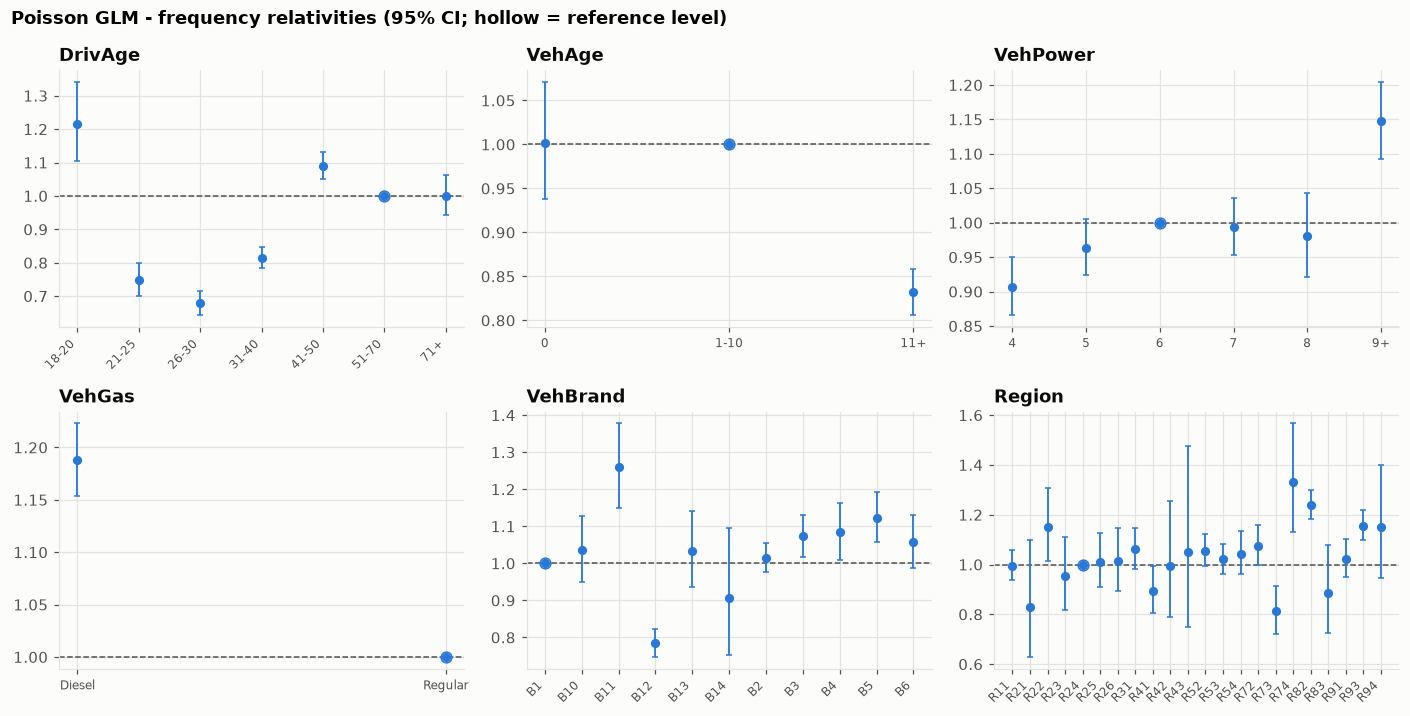

In [6]:
plot_relativities(glm, ["DrivAgeGLM", "VehAgeGLM", "VehPowerGLM", "VehGas", "VehBrand", "Region"],
                  title="Poisson GLM - frequency relativities (95% CI; hollow = reference level)",
                  name="03_glm_relativities")

In [7]:
rel.loc[[i for i in rel.index if i.startswith(("DrivAge", "VehAge", "VehGas"))],
        ["relativity", "ci_low", "ci_high", "p_value"]]

,relativity,ci_low,ci_high,p_value
VehAgeGLM[0],1.0021,0.9375,1.0712,0.9504
VehAgeGLM[11+],0.8318,0.8056,0.8588,0.0000
DrivAgeGLM[18-20],1.2167,1.1033,1.3418,0.0001
DrivAgeGLM[21-25],0.7491,0.7017,0.7997,0.0000
DrivAgeGLM[26-30],0.6784,0.6422,0.7166,0.0000
DrivAgeGLM[31-40],0.8155,0.7841,0.8481,0.0000
DrivAgeGLM[41-50],1.0891,1.0497,1.1301,0.0000
DrivAgeGLM[71+],1.0011,0.9421,1.0639,0.9706
VehGas[Diesel],1.1878,1.1536,1.2230,0.0000


**Why are the 21-40 relativities below 1?** The age relativities are *conditional on* the
bonus-malus. Young drivers have a high BM simply because they have not had time to earn bonus
(notebook 02, section 3.1), and the linear BM term already charges them for it. The cell below
combines the age relativity with the BM effect of the *average* BM of each age band, and
compares the result with the one-way observed frequency (both relative to the 51-70 band).

In [8]:
bands = glm_features(train)["DrivAgeGLM"]
beta_bm = rel.loc["BonusMalusGLM", "coef"]
summary = train.groupby(bands, observed=True).apply(lambda g: pd.Series({
    "mean_BM": g["BonusMalus"].clip(upper=150).mean(),
    "observed_freq": g["ClaimNb"].sum() / g["Exposure"].sum()}), include_groups=False)
ref = summary.loc["51-70"]
summary["age_relativity"] = [rel.loc[f"DrivAgeGLM[{b}]", "relativity"] if f"DrivAgeGLM[{b}]" in rel.index else 1.0
                             for b in summary.index]
summary["BM_effect_vs_ref"] = np.exp(beta_bm * (summary["mean_BM"] - ref["mean_BM"]))
summary["combined_GLM"] = summary["age_relativity"] * summary["BM_effect_vs_ref"]
summary["observed_one_way"] = summary["observed_freq"] / ref["observed_freq"]
summary.round(3)

,mean_BM,observed_freq,age_relativity,BM_effect_vs_ref,combined_GLM,observed_one_way
DrivAgeGLM,,,,,,
18-20,95.1350,0.2440,1.2170,3.1240,3.8010,3.7060
21-25,87.5710,0.1270,0.7490,2.5400,1.9020,1.9320
26-30,73.9400,0.0820,0.6780,1.7490,1.1870,1.2420
31-40,61.1970,0.0690,0.8160,1.2340,1.0070,1.0500
41-50,55.0780,0.0760,1.0890,1.0440,1.1370,1.1550
51-70,53.4980,0.0660,1.0000,1.0000,1.0000,1.0000
71+,52.3720,0.0600,1.0010,0.9700,0.9710,0.9030


**How to read the coefficients (mathematically and in practice)**

* **Intercept** $e^{\beta_0} = 0.0089$: the frequency of a hypothetical reference policy with BM = 0 and
  density = 1 - not meaningful alone; it just sets the base level.
* **Bonus-malus**: $e^{\hat\beta} = 1.0277$ per point, i.e. **+2.8% claims per BM point**. Over the
  whole bonus range, from 50 to 100: $1.0277^{50} \approx e^{0.0274 \times 50} \approx 3.9$, so a driver
  at 100 is expected to have ~4 times the claims of an otherwise identical driver at 50. This is
  the strongest factor in the tariff.
* **Density**: $e^{\hat\beta} = 1.078$ per unit of log-density. Since one unit of $\log$ is a factor
  $e \approx 2.7$ in density, going from a village of 50 inh./km² to a city of 5,000 ($\log$ ratio
  $\approx 4.6$) multiplies frequency by $1.078^{4.6} \approx 1.41$.
* **Diesel**: 1.19 (CI 1.15-1.22) - **+19%** versus petrol, larger than the one-way +14%
  because, other things equal, diesel cars are also less often in the (riskier) dense cities.
* **Vehicle age 11+**: 0.83 - older cars, driven less, have 17% fewer claims. New cars (0) are not
  different from 1-10 (p = 0.95: no evidence of an effect).
* **Vehicle power 9+**: 1.15; class 4: 0.91. **Brands**: B12 0.78, B11 1.26.
  **Regions**: most within ±15% of R24, with R82 (1.24) and R74 (1.33) the riskiest; small regions
  have wide intervals (little data).
* **Driver age** (reference 51-70): 18-20 is 1.22, while **21-40 is below 1** (0.68-0.82).
  This is *not* saying that young drivers are safe. See the cell above: young drivers have a high
  average BM (≈ 95 at 18-20 vs ≈ 53 at 51-70), and the BM term already multiplies their frequency
  by $\approx 3$. The *combined* GLM effect (age relativity × BM effect) reproduces the observed
  one-way pattern quite closely. The age relativity only measures the effect of age **beyond**
  what BM already explains.

**Real-world implication.** Because the factors are correlated, a GLM relativity must always be read
as "all other factors held fixed". Showing a relativity of 0.75 for drivers aged 21-25 to a business
audience without this context would be badly misleading. It also shows a limitation: the linear
BM term assumes a BM of 95 means the same for an 18-year-old (who could not have less) and for a
50-year-old (who had several claims). It does not - an **age × BM interaction** that the
main-effects GLM cannot represent.

### 2.4 Is the Poisson assumption reasonable? (over-dispersion)

The Poisson model assumes $\operatorname{Var}(N_i) = \mathbb{E}[N_i]$. A standard check is the
**Pearson dispersion statistic** $\hat\phi = \frac{1}{n-p}\sum_i \frac{(N_i-\hat\mu_i)^2}{\hat\mu_i}$,
which should be close to 1 if the assumption holds.

In [9]:
phi = res.pearson_chi2 / res.df_resid
print(f"Pearson dispersion: {phi:.3f}")

Pearson dispersion: 1.706


**Interpretation.** $\hat\phi \approx 1.7 > 1$: the data is **over-dispersed** - the claim counts
vary more than a Poisson model with these factors predicts. The reason is *unobserved
heterogeneity*: two drivers with identical rating factors still differ in skill, kilometres
driven, etc., so the true frequency varies within each cell.

*Consequences:*
* the **estimated relativities remain consistent** (the Poisson score equations only need the mean
  to be correctly specified - this is the quasi-likelihood argument);
* but the **standard errors are too small** by a factor $\sqrt{\hat\phi} \approx 1.3$: confidence intervals
  should be ~30% wider and some borderline p-values are optimistic. A quasi-Poisson or negative
  binomial model would correct this; for prediction the means are what matter, so we keep Poisson
  and keep this caveat in mind when reading p-values.

*Real-world meaning:* individual risk is only partly explained by tariff factors - which is exactly
why insurers also use **experience rating** (the bonus-malus system itself) to learn about each
driver over time.

## 3. Gradient boosting with LightGBM

### 3.1 Theory

**Decision trees.** A regression tree splits the population with yes/no questions
("BonusMalus > 95?", "DrivAge ≤ 21?") into groups (*leaves*) and predicts a constant per leaf.
A tree naturally captures non-linear effects and interactions (the split on age can be different
inside the high-BM and the low-BM branch), but a single tree is crude and unstable.

**Boosting.** Gradient boosting builds an *ensemble* of $M$ small trees, added one at a time:

$$\log \hat\lambda(x) = F_M(x) = F_0 + \nu \sum_{m=1}^{M} f_m(x)$$

Each new tree $f_m$ is fitted to the **negative gradient** of the loss with respect to the current
prediction - i.e. it moves the predictions in the direction that reduces the error the most
(gradient descent in the space of functions). The *learning rate* $\nu$ (e.g. 0.05) shrinks each
step so that the model improves slowly and generalises better.

**Same loss as the GLM.** We use LightGBM's `poisson` objective with a log link: it minimises
exactly the Poisson deviance. We feed it the frequency $N_i/E_i$ with **sample weight** $E_i$; the
weighted Poisson deviance of the frequency is proportional to the Poisson deviance of the counts
with offset $\log E_i$, so **both models answer the same statistical question** - the only difference
is how flexible the function $\eta(x)$ is: a sum of fixed terms (GLM) or a sum of trees (GBM).

**Over-fitting control (bias-variance trade-off).** A flexible model can fit noise. We control it
with:
* `num_leaves` - size of each tree (how complex the interactions can be);
* `min_child_samples` - minimum number of policies in a leaf (no leaf built on a handful of claims);
* `subsample`, `colsample_bytree` - each tree sees a random 80% of rows and features (adds randomness, reduces variance);
* `reg_lambda` - L2 penalty on leaf values; `cat_smooth` - shrinkage of categorical levels with little data;
* **early stopping** - trees are added until the deviance on an internal validation set (10% of
  the training data) stops improving for 100 rounds.

LightGBM grows trees *leaf-wise* and handles categorical variables natively (it finds the best
grouping of levels at each split), so brand and region need no one-hot encoding.

### 3.2 Hyper-parameter search

**Goal:** choose the model complexity on the *training* data only. We try a small grid of
settings, each evaluated with 3-fold cross-validation on the training set (the test set stays
untouched), and keep the one with the lowest mean Poisson deviance.

In [10]:
grid = [
    dict(num_leaves=15, min_child_samples=500, learning_rate=0.05),
    dict(num_leaves=31, min_child_samples=500, learning_rate=0.05),
    dict(num_leaves=63, min_child_samples=1000, learning_rate=0.05),
    dict(num_leaves=31, min_child_samples=2000, learning_rate=0.05),
    dict(num_leaves=31, min_child_samples=500, learning_rate=0.05, reg_lambda=10.0),
    dict(num_leaves=127, min_child_samples=2000, learning_rate=0.05),
]
null_factory = lambda: NullModel("Frequency", "Exposure")
rows = []
t0 = time.time()
for i, params in enumerate(grid):
    scores, _ = cross_validate(train, {"GBM": lambda p=params: FrequencyGBM(**p)}, frequency_scores,
                               null_factory, n_splits=3, verbose=False)
    s = scores[scores["model"] == "GBM"].groupby("metric")["value"].mean()
    rows.append({**params, "cv_poisson_deviance": s["poisson_deviance"], "cv_gini": s["gini"]})
search = pd.DataFrame(rows).sort_values("cv_poisson_deviance")
print(f"search time: {time.time() - t0:.0f}s")
search

search time: 97s


,num_leaves,min_child_samples,learning_rate,cv_poisson_deviance,cv_gini,reg_lambda
4,31,500,0.0500,0.4467,0.3277,10.0000
1,31,500,0.0500,0.4467,0.3272,NaN
0,15,500,0.0500,0.4470,0.3276,NaN
2,63,1000,0.0500,0.4471,0.3254,NaN
3,31,2000,0.0500,0.4474,0.3250,NaN
5,127,2000,0.0500,0.4476,0.3223,NaN


In [11]:
best = {k: v for k, v in search.iloc[0].items() if not k.startswith("cv_") and pd.notna(v)}
best = {k: (int(v) if k in ("num_leaves", "min_child_samples") else float(v)) for k, v in best.items()}
print("selected:", best)
(PROJECT_ROOT / "models").mkdir(exist_ok=True)
with open(PROJECT_ROOT / "models" / "frequency_gbm_params.json", "w") as f:
    json.dump(best, f, indent=2)

selected: {'num_leaves': 31, 'min_child_samples': 500, 'learning_rate': 0.05, 'reg_lambda': 10.0}


**Interpretation.** All configurations land within ~0.001 of each other in CV deviance: the result is
**not sensitive** to the hyper-parameters in this range (a flat optimum), which is reassuring.
Very large trees with large leaves (127 leaves / 2,000 policies) are slightly worse; the best is a
medium tree (31 leaves, ≥ 500 policies per leaf) with a stronger L2 penalty (`reg_lambda = 10`).
Early stopping chooses the number of trees, so the learning rate is kept fixed. The selected
parameters are saved to `models/frequency_gbm_params.json` for notebooks 05-06.

### 3.3 Fit the final GBM on the whole training set

In [12]:
t0 = time.time()
gbm = FrequencyGBM(**best).fit(train)
print(f"fitted in {time.time() - t0:.1f}s, trees used (early stopping): {gbm.best_iteration_}")
print(f"balance on train: predicted claims {(gbm.predict(train) * train['Exposure']).sum():,.1f} "
      f"vs observed {train['ClaimNb'].sum():,}")

fitted in 7.1s, trees used (early stopping): 456


balance on train: predicted claims 21,109.7 vs observed 21,126


## 4. Comparison on the test set

### 4.1 The metrics, in simple terms

* **Poisson deviance** (lower = better): the average "distance" between observed claim counts
  and predictions, measured in the way that is natural for Poisson data (2 × the log-likelihood
  gap with a perfect model). It rewards a model that is *accurate*, both in ranking and in level.
* **Deviance explained** $D^2 = 1 - D_\text{model}/D_\text{null}$: share of the deviance of the
  intercept-only model (everybody pays the same) removed by the model. A pseudo-$R^2$.
  For claim counts typical values are *small* (a few %) because whether a claim actually happens
  in a given year is mostly luck - no model can predict the accident itself, only the *propensity*.
* **Gini index** (higher = better): measures only the **ranking** - does the model put the
  risky customers above the safe ones? Sort policies from lowest to highest predicted frequency,
  plot cumulative exposure vs cumulative claims (the *Lorenz curve*); Gini = 1 - 2 × area under it.
  0 = random ranking. Commercially, ranking is what protects against adverse selection.
* **Balance** = predicted / observed total claims: a pricing model must reproduce the total.

In [13]:
models = {"Null": NullModel("Frequency", "Exposure").fit(train), "GLM": glm, "GBM": gbm}
preds = {k: m.predict(test) for k, m in models.items()}
results = pd.DataFrame({k: frequency_scores(test, p, preds["Null"]) for k, p in preds.items()}).T
results

,poisson_deviance,deviance_explained,gini,predicted_claims / observed_claims
Null,0.4806,0.0000,0.0057,0.9958
GLM,0.4604,0.0420,0.2812,0.9969
GBM,0.4512,0.0612,0.3205,0.9971


**Interpretation**

* Both models clearly beat the null model. The **GBM** reduces the test deviance from 0.4806 to
  **0.4512** (**D² = 6.1%**), the GLM to 0.4604 (**D² = 4.2%**): the GBM explains **~45% more** of
  the deviance than the GLM.
* **Gini: 0.320 (GBM) vs 0.281 (GLM)** - the GBM ranks customers better.
* **Balance**: both predict 99.7% of the claims observed on the test set - good calibration at portfolio
  level (the small gap is ordinary random variation of the test sample: the train frequency was 0.0736,
  test 0.0739).

*Why is D² so small?* Even a perfect tariff cannot predict *whether* an accident happens this year.
With a frequency of 7%, the claim count of a single policy is almost pure noise. The deviance of
the "oracle" model that knew each policy's true frequency would still be large. A few percent of
deviance explained is typical and substantial for motor frequency.

*Real-world meaning:* a 0.04 increase in Gini means the GBM separates good and bad risks
noticeably better. An insurer pricing with the GLM, competing against one pricing with the GBM,
would lose its best customers (overcharged by the GLM, undercut by the competitor) and keep the
under-priced bad ones: **adverse selection**.

### 4.2 Lorenz curves

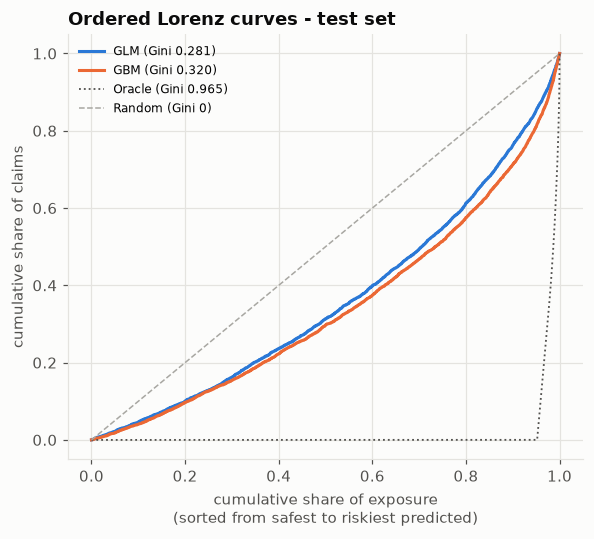

In [14]:
y, w = test["Frequency"].to_numpy(), test["Exposure"].to_numpy()
plot_lorenz(y, {"GLM": preds["GLM"], "GBM": preds["GBM"]}, w,
            title="Ordered Lorenz curves - test set", name="03_lorenz")

**Interpretation.** Read the curves from the right: the **20% of exposure that the GBM ranks as the
riskiest generates ~42% of the claims** (GLM: ~39%; see the lift table below). The further a
curve is from the diagonal, the better the segmentation. The oracle curve (Gini 0.965) is the
unreachable ideal of a model that knows in advance who will have a claim: the gap shows how much
of the claim experience is random.

### 4.3 Lift charts

**Goal:** check *calibration* by risk level. Policies are sorted by predicted frequency and cut
into 10 groups of equal exposure (deciles). For each decile we compare the average predicted
frequency (line) with the observed one (bars). A good model has (i) bars rising steeply from
decile 1 to 10 (strong segmentation) and (ii) the line on top of the bars (calibration).

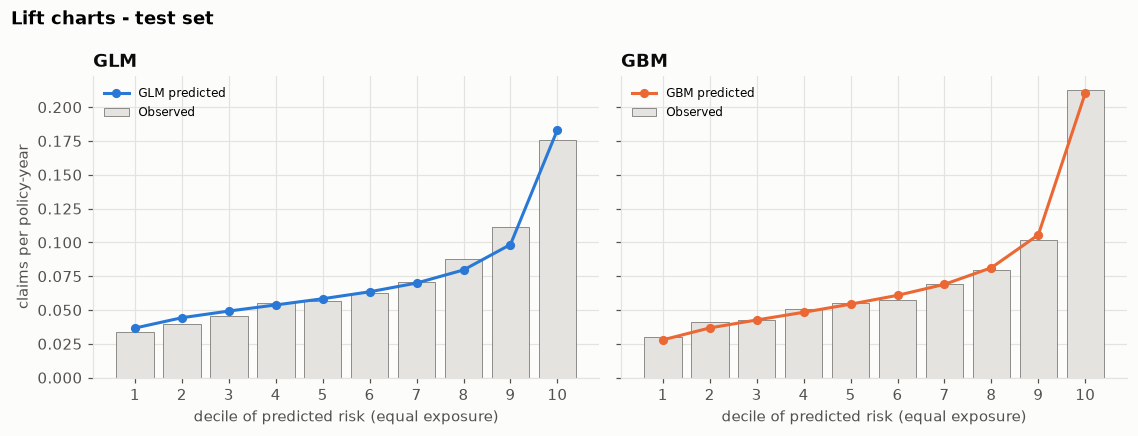

GLM                                  GBM                          
        weight predicted observed   lift     weight predicted observed   lift
bin                                                                          
1   7,140.5233    0.0367   0.0340 0.4603 7,139.6722    0.0279   0.0300 0.4054
2   7,140.1820    0.0443   0.0399 0.5399 7,141.4142    0.0368   0.0413 0.5588
3   7,140.5081    0.0492   0.0458 0.6194 7,140.0458    0.0426   0.0426 0.5759
4   7,141.1521    0.0538   0.0550 0.7444 7,140.9230    0.0483   0.0507 0.6857
5   7,140.4357    0.0583   0.0570 0.7710 7,140.6710    0.0543   0.0550 0.7445
6   7,140.5839    0.0635   0.0627 0.8486 7,139.9970    0.0609   0.0573 0.7748
7   7,140.7459    0.0699   0.0706 0.9547 7,141.2749    0.0690   0.0689 0.9319
8   7,140.1180    0.0796   0.0877 1.1859 7,140.7038    0.0813   0.0795 1.0759
9   7,140.6134    0.0984   0.1111 1.5022 7,139.7066    0.1056   0.1015 1.3735
10  7,141.1144    0.1832   0.1755 2.3734 7,141.5682    0.2104   0.2124 2.8733

In [15]:
lifts = {k: lift_table(y, preds[k], w, n_bins=10) for k in ["GLM", "GBM"]}
plot_lift(lifts, "Lift charts - test set", "claims per policy-year", name="03_lift")
pd.concat(lifts, axis=1).round(4)

**Interpretation**

* **Segmentation:** with the GBM the observed frequency goes from 0.030 in the safest decile to
  0.212 in the riskiest - a **ratio of ~7**. With the GLM, from 0.034 to 0.176 - a ratio of ~5.
  The GBM finds both safer and, especially, riskier groups.
* **Calibration:** both lines track the bars well. The GLM slightly *under*-predicts deciles 8-9
  (0.080 vs 0.088, 0.098 vs 0.111) and *over*-predicts decile 10: the GLM's rigid structure
  compresses the risk in the upper-middle part. The GBM is close in every decile, including the
  top one (0.210 vs 0.212).

*Real-world meaning:* the riskiest 10% of the portfolio has about 2.9 times the average frequency
according to the GBM and the data agrees - a tariff based on the GLM would under-price this group.

### 4.4 Double lift chart: where do the two models disagree, and who is right?

**Goal:** a head-to-head test. We sort policies by the ratio GBM prediction / GLM prediction.
In decile 1 the GBM thinks the policy is much *safer* than the GLM does; in decile 10 much
*riskier*. The observed frequency in those deciles tells us which model is closer to reality.
(All values are divided by the overall observed frequency.)

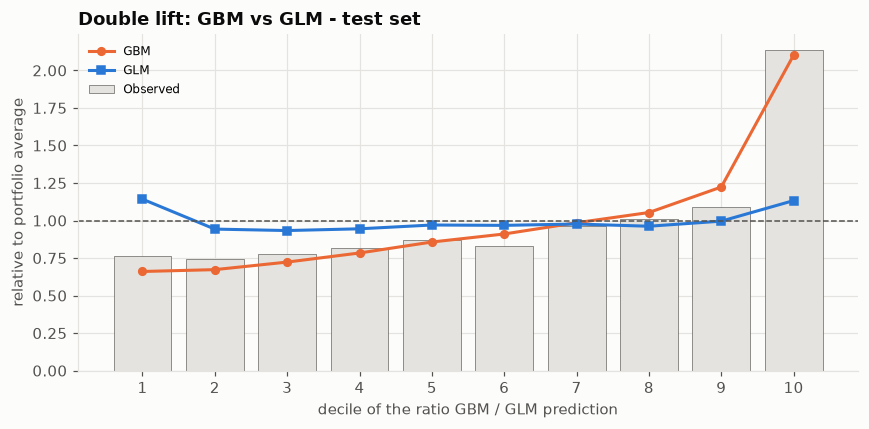

,weight,observed,model_a,model_b
bin,,,,
1,"7,140.5550",0.7630,0.6610,1.1420
2,"7,139.6650",0.7460,0.6730,0.9430
3,"7,141.5210",0.7770,0.7230,0.9330
4,"7,140.3940",0.8200,0.7840,0.9450
5,"7,140.8340",0.8680,0.8570,0.9700
6,"7,139.7840",0.8320,0.9100,0.9680
7,"7,140.6040",0.9600,0.9850,0.9770
8,"7,141.1760",1.0110,1.0530,0.9620
9,"7,140.5620",1.0870,1.2230,0.9960


In [16]:
dl = double_lift_table(y, preds["GBM"], preds["GLM"], w, n_bins=10)
plot_double_lift(dl, "GBM", "GLM", "Double lift: GBM vs GLM - test set", name="03_double_lift")
dl.round(3)

**Interpretation**

* **Decile 1** (GBM much more optimistic than the GLM): observed 0.76, GBM 0.66, GLM 1.14 - the GBM
  is far closer. The GLM would *overcharge* these customers by ~50%.
* **Decile 10** (GBM much more pessimistic): observed 2.14, GBM 2.10, GLM 1.13 - the GLM
  *under-prices* these customers by almost half; the GBM is almost exactly right.
* In the middle deciles the two models agree and are both close to the data.

This is the clearest evidence that the GBM's extra flexibility captures **real signal** and not
noise: where the two disagree, the data sides with the GBM. Commercially, decile 10 is where the
money is lost: these are the customers a GLM-priced insurer would attract and lose money on.

## 5. Conclusions

| | Poisson GLM | LightGBM (Poisson) |
|---|---|---|
| Test Poisson deviance | 0.4604 | **0.4512** |
| Deviance explained | 4.2% | **6.1%** |
| Gini index | 0.281 | **0.320** |
| Top-decile observed / predicted | 0.176 / 0.183 | 0.212 / 0.210 |
| Interpretability | **direct**: one relativity per level | needs SHAP / PDP (notebook 06) |

* The **bonus-malus** is by far the strongest frequency driver (+2.8% per point), followed by
  driver age, density, fuel, brand and region.
* The GBM is clearly better on every metric, and the double lift chart shows its advantage comes
  from real structure the GLM misses - very likely the **age × bonus-malus interaction** and
  non-linear BM effects (we verify this in notebook 06).
* The GLM remains valuable: transparent, stable, easy to file with a regulator. A common
  practical route is to use the GBM to *discover* interactions and add the most important ones
  to the GLM.

Next: **04 - Severity modelling**.